In [17]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# --- Parameter Initialization ---
N = 150         # 2D lattice contains N x N cells
KAGE = 10**-0.5 # aging rate constant for C cells
DELTA = 0       # spatial slack when inserting deleted C cell
BMIN = 2        # number of B's needed to become target (1, 2 or 3)
ATTCH = 0       # new C required to be attached to old C (0=NO/1=YES)
r0 = 10         # radius of initial B disk

# Controlled random numbers by use of a seed
np.random.seed(123)

# Grid initialization
A = np.ones((N, N))   # A initially in entire domain
B = np.zeros((N, N))  # B is injected at constant rate
C = np.zeros((N, N))  # C is the precipitation product

# Coordinates and center distances
X, Y = np.meshgrid(np.arange(1, N + 1), np.arange(1, N + 1))
rC = (X - N / 2) ** 2 + (Y - N / 2) ** 2 

# --- Create injection site at domain center ---
rho = np.sqrt((X - N / 2) ** 2 + (Y - N / 2) ** 2)
mask_disk = rho <= r0
A[mask_disk] = 0 
B[mask_disk] = 1 # small disk in middle contains B only

# 3x3 uniform convolution kernel to replace manual nested neighbor-counting loops
kernel = np.ones((3, 3))

# Setup Figure for Animation
fig, ax = plt.subplots(figsize=(6, 6))
# Initialize image object with dummy data to update dynamically
im = ax.imshow(np.zeros((N, N, 3)), extent=[0.5, N - 0.5, N - 0.5, 0.5])
ax.set_xlabel('x')
ax.set_ylabel('y')
title_text = ax.set_title('')

def update_simulation(frame_num):
    """Executes a single time-step simulation logic fully vectorized."""
    global A, B, C
    
    # 1. 2D Convolutions to compute 3x3 neighborhood sums over entire grid instantly
    sumA = convolve2d(A, kernel, mode='same')
    sumB = convolve2d(B, kernel, mode='same')
    sumC = convolve2d(C, kernel, mode='same')
    
    newA = A.copy()
    newB = B.copy()
    newC = C.copy()
    
    # 2. Vectorized rule updates for reactions and aging
    # Condition: reaction to C
    react_mask = (sumA > 0) & (sumB > 0) & (C == 0)
    # Condition: product ages
    age_mask = C > 0
    
    # Exclude boundary frames matching MATLAB's 2:N-1 interior logic
    grid_interior = np.zeros((N, N), dtype=bool)
    grid_interior[1:-1, 1:-1] = True
    
    # Apply changes to interior grid points
    react_final = react_mask & grid_interior
    newA[react_final] = 0
    newB[react_final] = 0
    newC[react_final] = 1
    
    age_final = age_mask & grid_interior
    newA[age_final] = 0
    newB[age_final] = 0
    newC[age_final] = C[age_final] + 1
    
    # Synchronize primary trackers before target identification stage
    A, B, C = newA, newB, newC
    
    # 3. Vectorized Target Selection (Randomly replace one fresh C cell with B)
    target_candidates = (C > 0) & (sumB >= BMIN) & grid_interior
    y_targets, x_targets = np.where(target_candidates)
    m = len(x_targets)
    
    if m > 0:
        Ctarget = C[y_targets, x_targets]
        Cprobs = np.exp(-KAGE * (Ctarget - 1.0))
        probs = Cprobs / np.sum(Cprobs)
        
        # Select target element index
        ti = np.random.choice(m, p=probs)
        target_x, target_y = x_targets[ti], y_targets[ti]
        
        newB[target_y, target_x] = 1 
        newC[target_y, target_x] = 0 
        
        # 4. Vectorized Placement into nearest available A site
        y_avail, x_avail = np.where((A == 1) & grid_interior)
        
        if len(x_avail) > 0:
            distances = np.sqrt((x_avail - target_x)**2 + (y_avail - target_y)**2)
            dsqfinal = np.min(distances)
            
            # Check attachment configurations and distance bounds simultaneously
            valid_p = (sumC[y_avail, x_avail] >= ATTCH) & (distances <= dsqfinal + DELTA)
            xp, yp = x_avail[valid_p], y_avail[valid_p]
            
            if len(xp) > 0:
                ppick = np.random.randint(0, len(xp))
                newA[yp[ppick], xp[ppick]] = 0
                newB[yp[ppick], xp[ppick]] = 0
                newC[yp[ppick], xp[ppick]] = 1

    A, B, C = newA, newB, newC

    # 5. Build RGB Render Array
    c_mask = C > 0
    dum1 = np.zeros_like(C)
    if np.any(c_mask):
        minC, maxC = np.min(C[c_mask]), np.max(C[c_mask])
        if maxC != minC:
            dum1[c_mask] = 1.0 - (C[c_mask] - minC) / (maxC - minC)
        else:
            dum1[c_mask] = 1.0
            
    R = 0.8 * A + dum1
    G = 0.8 * A + dum1 * 0.6 + 0.6 * B
    B_ch = 0.8 * A + B
    img1 = np.clip(np.stack([R, G, B_ch], axis=-1), 0, 1)
    
    # Check breakdown condition to halt if termination distance reached
    rmaxC = np.max(rC[C > 0]) if np.any(C > 0) else 0
    if rmaxC >= (N / 2 - 2) ** 2:
        anim.event_source.stop()

    # Update frame configurations
    im.set_array(img1)
    title_text.set_text(f't={frame_num}, k={KAGE:2.3e}, $\\delta$={DELTA}')
    return [im, title_text]

# Construct and compile the animation player
anim = FuncAnimation(fig, update_simulation, frames=250, interval=30, blit=True)
plt.close()

# Generate high-performance media controls inside your notebook output
HTML(anim.to_jshtml())

In [53]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# --- Physics-Informed Parameters ---
N = 250
DIFFUSION_RATE = 0.15   # How fast the solute redistributes
DEPLETION_RATE = 0.4    # How much solute a growing crystal consumes
GROWTH_THRESHOLD = 0.35 # Minimum solute needed to allow crystal advance
P_BRANCH = 0.10         # Probability of a branch splitting
BRANCH_ANGLE = np.pi / 6
CURVATURE = 0.03

np.random.seed(42)

# Grid 1: Solute Concentration (U), initialized to a supersaturated state (1.0)
U = np.ones((N, N), dtype=float)
# Grid 2: Crystal Matrix (C), 0 = liquid, integers = crystal grains
C = np.zeros((N, N), dtype=int)

# 9-point Laplacian kernel for solving the Diffusion Equation
laplacian_kernel = np.array([[0.05, 0.10, 0.05],
                             [0.10, -0.60, 0.10],
                             [0.05, 0.10, 0.05]])

active_tips = []
grain_counter = 0

# Seed along the top boundary
for x_seed in np.linspace(15, N-15, 6):
    grain_counter += 1
    ix = int(x_seed)
    active_tips.append({
        'pos': np.array([0.0, x_seed]),
        'dir': np.array([1.0, np.random.uniform(-0.1, 0.1)]),
        'grain': grain_counter
    })
    C[0, ix] = grain_counter
    U[0, ix] = 0.0 # Seed consumes initial solute

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(C, cmap='bone_r', extent=[0, N, N, 0], vmin=0, vmax=50)
ax.set_title("Physics-Informed Dendritic Growth (Solute Depletion)")
ax.set_xlabel("x")
ax.set_ylabel("y")

def update_riboflavin(frame_num):
    global grain_counter, active_tips, U, C
    
    # 1. PHYSICS STEP: Solve the Diffusion Equation for the solute field
    # dU/dt = D * Laplacian(U)
    diffusion = convolve2d(U, laplacian_kernel, mode='same')
    U += DIFFUSION_RATE * diffusion
    U = np.clip(U, 0.0, 1.0) # Keep solute bounded
    
    next_tips = []
    np.random.shuffle(active_tips)
    
    # 2. GROWTH STEP: Tips advance based on local solute availability
    for tip in active_tips:
        current_angle = np.arctan2(tip['dir'][0], tip['dir'][1])
        current_angle += np.random.uniform(-CURVATURE, CURVATURE)
        tip['dir'] = np.array([np.sin(current_angle), np.cos(current_angle)])
        
        # Calculate next prospective physical coordinate
        new_pos = tip['pos'] + tip['dir'] * 1.2
        ny, nx = int(np.round(new_pos[0])), int(np.round(new_pos[1]))
        
        if ny < 0 or ny >= N or nx < 0 or nx >= N:
            continue
        if C[ny, nx] > 0:
            continue
            
        # THERMODYNAMIC CHECK: Can it grow here?
        # If the local solute concentration is too low (depleted by a neighbor), growth stalls.
        if U[ny, nx] < GROWTH_THRESHOLD:
            next_tips.append(tip) # Keep tip alive, but don't advance this frame
            continue
            
        # Freeze solute into solid crystal
        C[ny, nx] = tip['grain']
        U[ny, nx] -= DEPLETION_RATE # Consume chemical solute
        
        tip['pos'] = new_pos
        next_tips.append(tip)
        
        # 3. BRANCHING STEP
        if np.random.rand() < P_BRANCH:
            grain_counter += 1
            side = 1 if np.random.rand() > 0.5 else -1
            new_angle = current_angle + (side * BRANCH_ANGLE)
            new_dir = np.array([np.sin(new_angle), np.cos(new_angle)])
            
            next_tips.append({
                'pos': new_pos.copy(),
                'dir': new_dir,
                'grain': grain_counter
            })
            
    active_tips = next_tips
    
    # Force a minimum solute level inside solid crystal to keep physics stable
    U[C > 0] = 0.0
    
    im.set_array(C)
    return [im]

anim = FuncAnimation(fig, update_riboflavin, frames=220, interval=30, blit=True)
plt.close()

HTML(anim.to_jshtml())

Animation size has reached 21137333 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


Simulating...
  step 0/12000  |  solid=0.0081  phi_max=1.000
  step 6000/12000  |  solid=0.0081  phi_max=1.000
  step 12000/12000  |  solid=0.0081  phi_max=1.000
Done — 201 frames


Animation size has reached 21192028 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


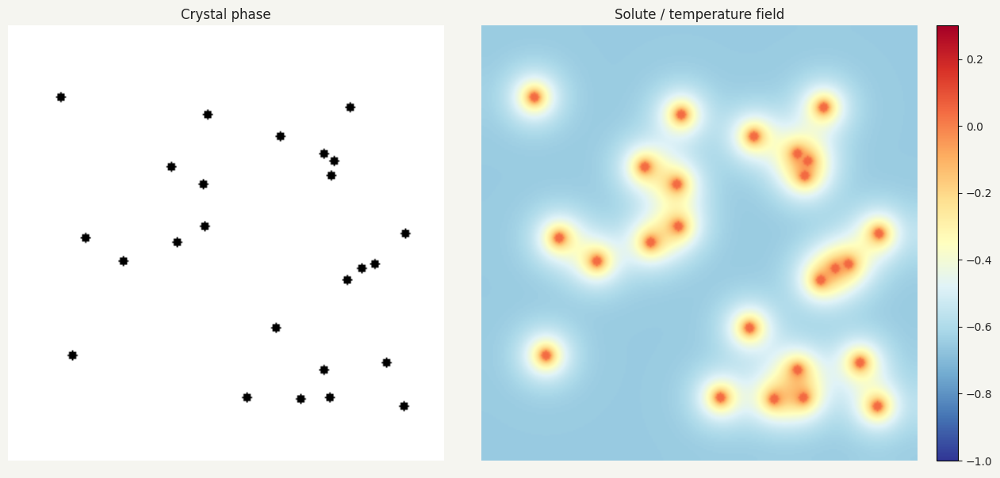

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# =============================================================================
# PARAMETERS — tuned for fern/snowflake dendrites like your video
# =============================================================================
N           = 300        # Grid size (increase for more detail, slower)
DX          = 0.4
DT          = 0.002

STEPS       = 12000
FRAME_EVERY = 60

# Phase field
TAU         = 0.0003     # Relaxation time
W           = 0.014      # Interface width
DELTA       = 0.06       # Anisotropy strength — higher = sharper needles
J           = 6          # Symmetry: 6=hexagonal, 4=square
KAPPA       = 1.6        # Latent heat coupling
ALPHA       = 0.9        # Undercooling → growth coupling

# Noise — essential for side-branch instability
NOISE_AMP   = 0.008      # Random perturbation on interface; triggers side branches

# Nucleation — multiple seeds like your video
N_SEEDS     = 25         # Number of nucleation sites
SEED_RADIUS = 3          # Pixels per seed
UNDERCOOLING = -0.65     # Bulk undercooling (more negative = faster/spikier)

# Each seed gets a random orientation → different crystal arms per nucleus
rng = np.random.default_rng(42)
seed_positions = rng.integers(20, N - 20, size=(N_SEEDS, 2))
seed_thetas    = rng.uniform(0, 2 * np.pi / J, size=N_SEEDS)  # random orientation

# =============================================================================
# INITIALIZATION
# =============================================================================
phi = np.zeros((N, N))
u   = np.full((N, N), UNDERCOOLING)
theta_field = np.zeros((N, N))   # orientation per cell (for per-crystal anisotropy)

Y, X = np.ogrid[:N, :N]
for (cy, cx), th in zip(seed_positions, seed_thetas):
    r2 = (X - cx)**2 + (Y - cy)**2
    mask = r2 <= SEED_RADIUS**2
    phi[mask] = 1.0
    u[mask]   = 0.0
    theta_field[mask] = th

# =============================================================================
# CORE FUNCTIONS
# =============================================================================
def laplacian(f):
    lap = np.empty_like(f)
    lap[1:-1,1:-1] = (
        f[2:,1:-1] + f[:-2,1:-1] +
        f[1:-1,2:] + f[1:-1,:-2] -
        4.0 * f[1:-1,1:-1]
    ) / DX**2
    # Neumann BC
    lap[0,:]  = lap[1,:]
    lap[-1,:] = lap[-2,:]
    lap[:,0]  = lap[:,1]
    lap[:,-1] = lap[:,-2]
    return lap

def simulation_step(phi, u, theta_field):
    # --- Gradient of phi ---
    gx = np.zeros_like(phi)
    gy = np.zeros_like(phi)
    gx[1:-1,1:-1] = (phi[1:-1,2:] - phi[1:-1,:-2]) / (2*DX)
    gy[1:-1,1:-1] = (phi[2:,1:-1] - phi[:-2,1:-1]) / (2*DX)

    # --- Anisotropy: orientation is per-nucleus via theta_field ---
    # Propagate orientation outward from solid (so growing tips inherit seed orientation)
    # Simple: use interface gradient angle minus local crystal orientation
    grad_angle = np.arctan2(gy, gx)
    angle = J * (grad_angle - theta_field)

    eps  = W * (1.0 + DELTA * np.cos(angle))
    deps = W * (-DELTA * J * np.sin(angle))   # d(eps)/d(local_angle)

    # --- Anisotropic diffusion: div(eps^2 * grad phi) ---
    eps2_gx = eps**2 * gx
    eps2_gy = eps**2 * gy
    div = np.zeros_like(phi)
    div[1:-1,1:-1] = (
        (eps2_gx[1:-1,2:] - eps2_gx[1:-1,:-2]) / (2*DX) +
        (eps2_gy[2:,1:-1] - eps2_gy[:-2,1:-1]) / (2*DX)
    )

    # --- Rotation correction (Kobayashi term) ---
    Bx = eps * deps * gy
    By = eps * deps * gx
    rot = np.zeros_like(phi)
    rot[1:-1,1:-1] = (
         (Bx[1:-1,2:] - Bx[1:-1,:-2]) / (2*DX) -
         (By[2:,1:-1] - By[:-2,1:-1]) / (2*DX)
    )

    # --- Driving force with noise (Karma-Rappel noise for side branches) ---
    m = (ALPHA / np.pi) * np.arctan(10.0 * (-u))
    noise = NOISE_AMP * rng.standard_normal(phi.shape)
    # Only apply noise at the interface
    interface = phi * (1 - phi)
    bulk = interface * (phi - 0.5 + m + noise * interface)

    dphi = (div + rot + bulk) / TAU

    # --- Temperature / solute field ---
    du = laplacian(u) + 0.5 * dphi

    phi_new = np.clip(phi + DT * dphi, 0.0, 1.0)
    u_new   = u + DT * du

    # --- Propagate crystal orientation into newly solidified cells ---
    # New solid cells adopt orientation from their most-solid neighbor
    new_solid = (phi_new > 0.3) & (phi < 0.3)
    if new_solid.any():
        # Weighted average of neighbor orientations (simple: copy from phi-weighted neighbors)
        theta_avg = np.zeros_like(theta_field)
        wt = np.zeros_like(theta_field)
        for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
            nb_phi  = np.roll(np.roll(phi,  di, 0), dj, 1)
            nb_th   = np.roll(np.roll(theta_field, di, 0), dj, 1)
            theta_avg += nb_phi * nb_th
            wt        += nb_phi
        wt = np.where(wt > 0, wt, 1)
        theta_field = np.where(new_solid, theta_avg / wt, theta_field)

    return phi_new, u_new, theta_field

# =============================================================================
# RUN
# =============================================================================
frames_phi, frames_u = [], []
print("Simulating...")
for s in range(STEPS + 1):
    if s % FRAME_EVERY == 0:
        frames_phi.append(phi.copy())
        frames_u.append(u.copy())
        if s % 2000 == 0:
            print(f"  step {s}/{STEPS}  |  solid={phi.mean():.4f}  phi_max={phi.max():.3f}")
    phi, u, theta_field = simulation_step(phi, u, theta_field)

print(f"Done — {len(frames_phi)} frames")

# =============================================================================
# ANIMATE — styled like your microscopy video (light bg, dark crystals)
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
fig.patch.set_facecolor('#f5f5f0')
for ax in (ax1, ax2):
    ax.set_facecolor('#f5f5f0')
    ax.axis('off')

# Invert colormap so solid = dark on light background, like real microscopy
im1 = ax1.imshow(1 - frames_phi[0], cmap='gray', vmin=0, vmax=1,
                  origin='lower', interpolation='bilinear')
im2 = ax2.imshow(frames_u[0], cmap='RdYlBu_r', vmin=-1, vmax=0.3,
                  origin='lower', interpolation='bilinear')

ax1.set_title('Crystal phase', color='#222', fontsize=12)
ax2.set_title('Solute / temperature field', color='#222', fontsize=12)

cb = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
cb.ax.yaxis.set_tick_params(color='#222', labelcolor='#222')

txt = fig.text(0.5, 0.01, '', ha='center', color='#666', fontsize=10)
plt.tight_layout()

def update(i):
    im1.set_data(1 - frames_phi[i])
    im2.set_data(frames_u[i])
    txt.set_text(f'step {i * FRAME_EVERY}')
    return im1, im2, txt

ani = animation.FuncAnimation(fig, update, frames=len(frames_phi),
                               interval=50, blit=True)
HTML(ani.to_jshtml())